# 6G Traffic IPP Parameter Tuning and Augmentation

This notebook demonstrates how we tuned the KTH Interrupted Poisson Process (IPP) to generate realistic, yet smoother instantaneously synthesized micro-bursts from the 5-minute aggregated network macroscopic measurements.

It covers:
1. **Aggregating** the original empirical traffic dataset.
2. **Visualizing and Tuning** the Continuous-Time Markov Chain (CTMC) `tau` (OFF->ON rate) and `zeta` (ON->OFF rate) parameters to remove massive sparse spikes.
3. **Augmenting** the complete 86-sector dataset with these smoothed synthesized parameters.


In [ ]:
# Run from repo root so that data/ and src/ resolve
import os, sys
if os.path.basename(os.getcwd()) == 'notebooks':
    os.chdir('..')
sys.path.insert(0, os.getcwd())

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import warnings

from src.data_loader import load_and_aggregate_data
from src.config import KTHParams
from src.utils import rolling_variance_proxy
from src.kth_ipp import generate_fine_series_from_coarse

warnings.filterwarnings('ignore')

# 1. Load the original coarse dataset and aggregate total macroscopic traffic
print("Loading and aggregating empirical database...")
df_agg = load_and_aggregate_data()

# Limit to the first 1000 coarse measurements for fast, responsive visualization testing
coarse_agg = df_agg["trafic_mbps"].to_numpy()[:1000] 
print(f"Loaded {len(coarse_agg)} aggregated 5-min averages.")


Loading and aggregating empirical database...
Loaded 287 aggregated 5-min averages.


## 1. Comparing IPP Parameter Behaviors

To accurately simulate the telecommunication link, the generator solves for local lambda and exponential payload amounts to exactly match the empirical mean and variance bit-by-bit.
However, if the CTMC flips too slowly (e.g. `tau=1/30` and `zeta=1/10`), the ON bursts become extremely dense followed by long intervals of 0 traffic, creating artificial massive Pareto spikes. 

By increasing the rate of switching (e.g. `tau=0.5` and `zeta=0.5`), the process generates rapid, balanced micro-bursts that smooth out across a 60-second granularity while still perfectly retaining the aggregated volume exactly.


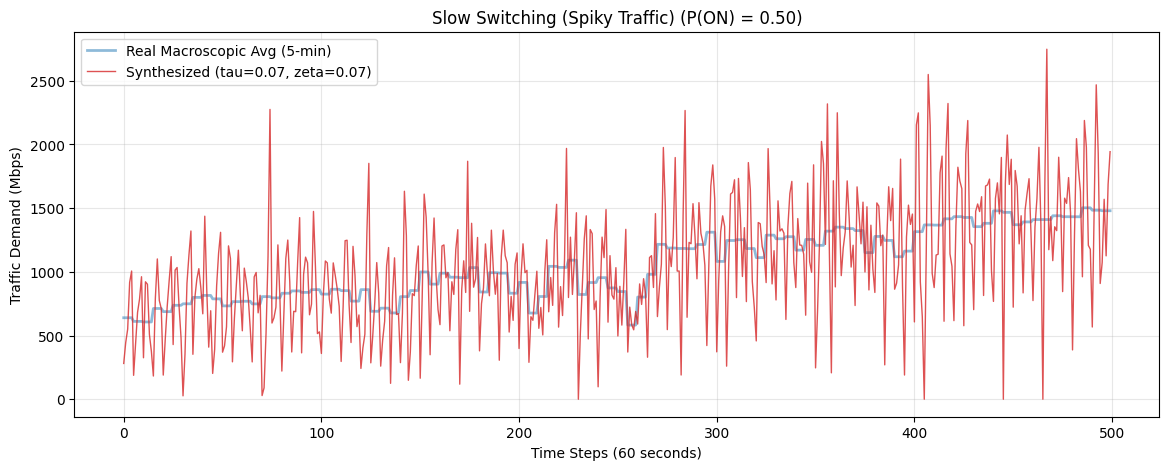

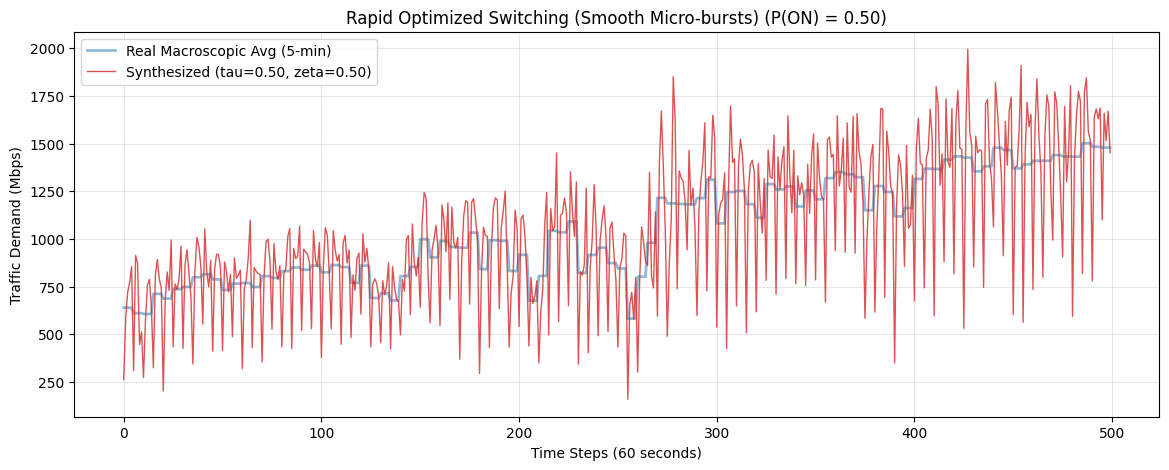

In [2]:
def plot_ipp_simulation(coarse_samples, tau, zeta, title=""):
    # Target Granularity: 60s
    p_macro = KTHParams(
        T=300.0,       # Coarse average duration (5 mins)
        tau=tau,       
        zeta=zeta,     
        dt=60.0        # Granularity
    )

    fine_macro, _, _ = generate_fine_series_from_coarse(
        coarse_samples,
        coarse_var=rolling_variance_proxy(coarse_samples, k=6, var_floor_ratio=0.01, tau=p_macro.tau, zeta=p_macro.zeta, T=p_macro.T),
        p=p_macro,
        seed=42
    )

    steps = int(p_macro.T / p_macro.dt)
    coarse_step = np.repeat(coarse_samples, steps)
    fine_series = fine_macro[:len(coarse_step)]

    # Slice for clear visibility (about ~8 hours)
    plot_len = min(500, len(coarse_step))
    
    plt.figure(figsize=(14, 5))
    plt.plot(coarse_step[:plot_len], label="Real Macroscopic Avg (5-min)", alpha=0.5, color='tab:blue', linewidth=2)
    plt.plot(fine_series[:plot_len], label=f"Synthesized (tau={tau:.2f}, zeta={zeta:.2f})", alpha=0.8, color='tab:red', linewidth=1)
    
    plt.title(f"{title} (P(ON) = {tau/(tau+zeta):.2f})")
    plt.xlabel("Time Steps (60 seconds)")
    plt.ylabel("Traffic Demand (Mbps)")
    plt.legend()
    plt.grid(True, alpha=0.3)
    plt.show()

# Observe the extreme spikiness of the original settings
plot_ipp_simulation(coarse_agg, tau=1/15, zeta=1/15, title="Slow Switching (Spiky Traffic)")

# Observe the highly smoothed, robust traffic generation using rapid switching
plot_ipp_simulation(coarse_agg, tau=0.5, zeta=0.5, title="Rapid Optimized Switching (Smooth Micro-bursts)")


## 2. Parameter Integration and Full Augmentation

With `tau=0.5` and `zeta=0.5` isolated as our ideal smoothed IPP configuration, we deploy `generate_augmented.py` across the application. 
During augmentation, the script isolates all **86 independent sectors** from the parent `histo_trafic.csv`, computes rolling variances individually, and computationally unfolds every sector's 5-minute averages into continuous 60-second IPP sequences. 

*(Note: In the project pipeline, this processing is done natively via `python generate_augmented.py`, generating `data/augmented_data.csv` which seamlessly injects right into the SARIMA and Chronos 2 evaluation loops.)*
